<a href="https://colab.research.google.com/github/Maaz111187/Tomato-leaf-disease-classifier./blob/main/Crop_Leaf_Disease_Classifier_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import kagglehub

path = kagglehub.dataset_download("emmarex/plantdisease")
print("Dataset folder:", path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset folder: /kaggle/input/plantdisease


In [5]:
!pip install -q kagglehub

In [6]:
import kagglehub
print(kagglehub.dataset_download("emmarex/plantdisease"))

Using Colab cache for faster access to the 'plantdisease' dataset.
/kaggle/input/plantdisease


In [7]:
from pathlib import Path

dataset_path = Path("/kaggle/input/plantdisease")

print("Top-level items:")
for item in list(dataset_path.iterdir())[:20]:
    print(item.name)

print("\nTomato folders:")
for folder in dataset_path.rglob("*"):
    if folder.is_dir() and "tomato" in folder.name.lower():
        print(folder)

Top-level items:
PlantVillage
plantvillage

Tomato folders:
/kaggle/input/plantdisease/PlantVillage/Tomato_Leaf_Mold
/kaggle/input/plantdisease/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus
/kaggle/input/plantdisease/PlantVillage/Tomato_Bacterial_spot
/kaggle/input/plantdisease/PlantVillage/Tomato_Septoria_leaf_spot
/kaggle/input/plantdisease/PlantVillage/Tomato_healthy
/kaggle/input/plantdisease/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite
/kaggle/input/plantdisease/PlantVillage/Tomato_Early_blight
/kaggle/input/plantdisease/PlantVillage/Tomato__Target_Spot
/kaggle/input/plantdisease/PlantVillage/Tomato_Late_blight
/kaggle/input/plantdisease/PlantVillage/Tomato__Tomato_mosaic_virus
/kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato_Leaf_Mold
/kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus
/kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato_Bacterial_spot
/kaggle/input/plantdisease/plantvillage/PlantVillage/To

In [8]:
from pathlib import Path

data_dir = Path("/kaggle/input/plantdisease/PlantVillage")

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir() and "tomato" in folder.name.lower():
        image_count = sum(
            1 for file in folder.iterdir()
            if file.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        print(f"{folder.name}: {image_count} images")

Tomato_Bacterial_spot: 2127 images
Tomato_Early_blight: 1000 images
Tomato_Late_blight: 1909 images
Tomato_Leaf_Mold: 952 images
Tomato_Septoria_leaf_spot: 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images
Tomato__Target_Spot: 1404 images
Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images
Tomato__Tomato_mosaic_virus: 373 images
Tomato_healthy: 1591 images


In [9]:
import tensorflow as tf

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_ds).numpy())

Found 20638 files belonging to 15 classes.
Using 16511 files for training.
Found 20638 files belonging to 15 classes.
Using 4127 files for validation.
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Training batches: 516
Validation batches: 129


In [10]:
from pathlib import Path
import shutil
import tensorflow as tf

source_dir = Path("/kaggle/input/plantdisease/PlantVillage")
tomato_dir = Path("/content/tomato_data")

tomato_folders = [
    folder for folder in source_dir.iterdir()
    if folder.is_dir() and folder.name.lower().startswith("tomato")
]

for folder in tomato_folders:
    shutil.copytree(folder, tomato_dir / folder.name, dirs_exist_ok=True)

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    tomato_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    tomato_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

class_names = train_ds.class_names
print("Number of classes:", len(class_names))
print("Classes:", class_names)

Found 16011 files belonging to 10 classes.
Using 12809 files for training.
Found 16011 files belonging to 10 classes.
Using 3202 files for validation.
Number of classes: 10
Classes: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


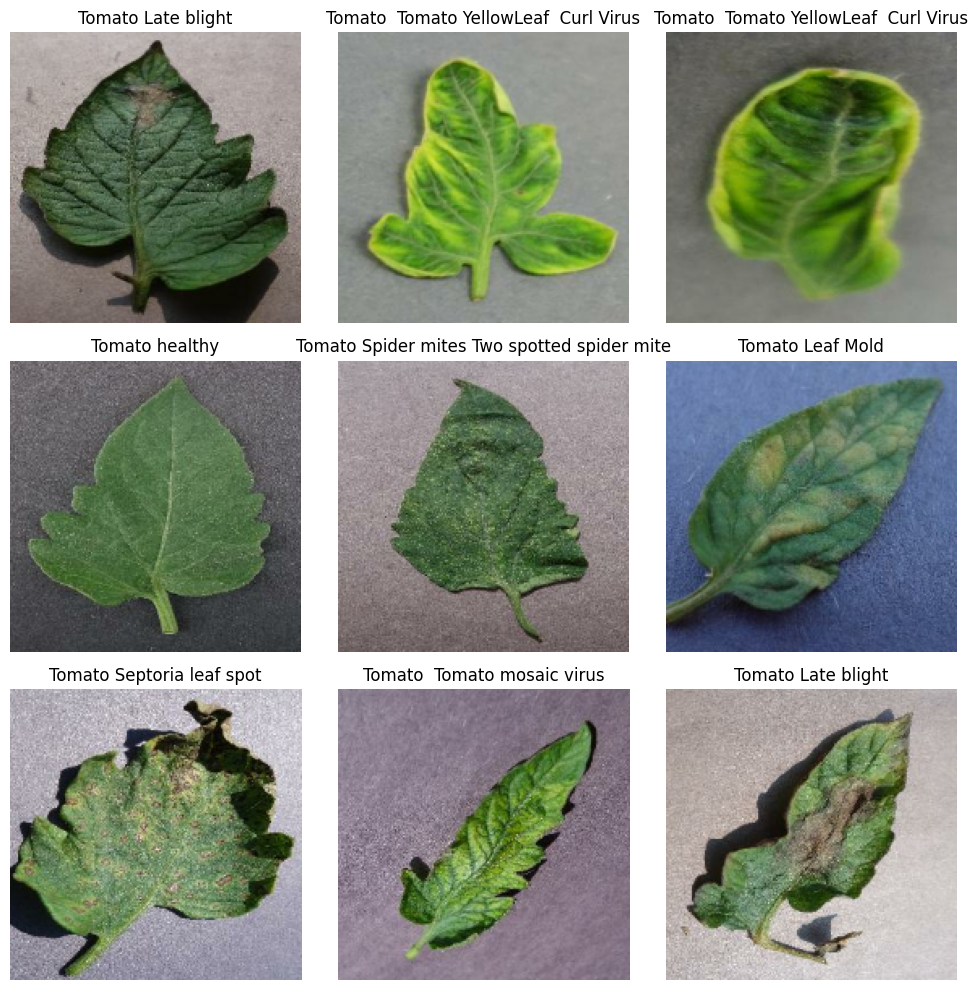

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])].replace("_", " "))
        plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.1),
])

train_ds = train_ds.map(
    lambda images, labels: (data_augmentation(images, training=True), labels),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)

validation_ds = validation_ds.prefetch(AUTOTUNE)

print("Training and validation pipelines are ready.")

Training and validation pipelines are ready.


In [13]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(180, 180, 3),
    include_top=False,
    weights="imagenet",
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(180, 180, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

/tmp/ipykernel_2628/1739174438.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10
401/401 ━━━━━━━━━━━━━━━━━━━━ 138s 283ms/step - accuracy: 0.6947 - loss: 0.9165 - val_accuracy: 0.8204 - val_loss: 0.5590
Epoch 2/10
401/401 ━━━━━━━━━━━━━━━━━━━━ 81s 201ms/step - accuracy: 0.8232 - loss: 0.5398 - val_accuracy: 0.8582 - val_loss: 0.4542
Epoch 3/10
401/401 ━━━━━━━━━━━━━━━━━━━━ 81s 202ms/step - accuracy: 0.8401 - loss: 0.4653 - val_accuracy: 0.8501 - val_loss: 0.4469
Epoch 4/10
401/401 ━━━━━━━━━━━━━━━━━━━━ 81s 201ms/step - accuracy: 0.8549 - loss: 0.4292 - val_accuracy: 0.8526 - val_loss: 0.4316
Epoch 5/10
401/401 ━━━━━━━━━━━━━━━━━━━━ 81s 201ms/step - accuracy: 0.8615 - loss: 0.4102 - val_accuracy: 0.8620 - val_loss: 0.4141
Epoch 6/10
401/401 ━━━━━━━━━━━━━━━━━━━━ 82s 200ms/step - accuracy: 0.8688 - loss: 0.3926 - val_accuracy: 0.8654 - val_loss: 0.3937
Epoch 7/10
401/401 ━━━━━━━━━━━━━━━━━━━━ 79s 198ms/step - accuracy: 0.8734 - loss: 0.3696 - val_accuracy: 0.8688 - val_loss: 0.3995
Epoch 8/10
401/401 ━━━━━━━━━━━━━━━━━━━━ 83s 201ms/step - accuracy: 0.8714 - loss: 

In [15]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy() for _, labels in validation_ds
])

y_prob = model.predict(validation_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=3,
))

101/101 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot      0.135     0.164     0.148       421
                        Tomato_Early_blight      0.039     0.027     0.032       185
                         Tomato_Late_blight      0.106     0.100     0.103       370
                           Tomato_Leaf_Mold      0.069     0.063     0.066       191
                  Tomato_Septoria_leaf_spot      0.106     0.108     0.107       372
Tomato_Spider_mites_Two_spotted_spider_mite      0.094     0.099     0.097       322
                        Tomato__Target_Spot      0.109     0.098     0.103       287
      Tomato__Tomato_YellowLeaf__Curl_Virus      0.217     0.208     0.212       672
                Tomato__Tomato_mosaic_virus      0.000     0.000     0.000        68
                             Tomato_healthy      0.104     0.127     0.115       314

                    

In [16]:
validation_ds = tf.keras.utils.image_dataset_from_directory(
    tomato_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    shuffle=False,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

y_true = np.concatenate([labels.numpy() for _, labels in validation_ds])
y_prob = model.predict(validation_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=3,
))

Found 16011 files belonging to 10 classes.
Using 3202 files for validation.
101/101 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot      0.000     0.000     0.000         0
                        Tomato_Early_blight      0.000     0.000     0.000         0
                         Tomato_Late_blight      0.000     0.000     0.000         0
                           Tomato_Leaf_Mold      0.000     0.000     0.000         0
                  Tomato_Septoria_leaf_spot      0.000     0.000     0.000         0
Tomato_Spider_mites_Two_spotted_spider_mite      0.000     0.000     0.000         0
                        Tomato__Target_Spot      0.000     0.000     0.000         0
      Tomato__Tomato_YellowLeaf__Curl_Virus      0.984     0.965     0.975      1238
                Tomato__Tomato_mosaic_virus      1.000     0.539     0.700       373
                             To

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [17]:
validation_ds = tf.keras.utils.image_dataset_from_directory(
    tomato_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    shuffle=True,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

y_true = []
y_pred = []

for images, labels in validation_ds:
    probabilities = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probabilities, axis=1))

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=3,
    zero_division=0,
))

Found 16011 files belonging to 10 classes.
Using 3202 files for validation.
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot      0.787     0.957     0.864       421
                        Tomato_Early_blight      0.844     0.584     0.690       185
                         Tomato_Late_blight      0.945     0.889     0.916       370
                           Tomato_Leaf_Mold      0.903     0.827     0.863       191
                  Tomato_Septoria_leaf_spot      0.839     0.852     0.845       372
Tomato_Spider_mites_Two_spotted_spider_mite      0.821     0.866     0.843       322
                        Tomato__Target_Spot      0.770     0.686     0.726       287
      Tomato__Tomato_YellowLeaf__Curl_Virus      0.983     0.945     0.964       672
                Tomato__Tomato_mosaic_virus      1.000     0.529     0.692        68
                             Tomato_healthy      0.807     0.984     0.88

In [18]:
import json

model.save("/content/tomato_leaf_disease_model.keras")

with open("/content/class_names.json", "w") as file:
    json.dump(class_names, file, indent=2)

print("Saved model and class labels.")

Saved model and class labels.


In [19]:
from google.colab import files

files.download("/content/tomato_leaf_disease_model.keras")
files.download("/content/class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>